# CodeNova Task 4 – Customer Segmentation Study

**Dataset:** Customer Purchase Behavior (`shopping_trends.csv`) – 3,900 customer records.

This notebook explores customer purchase patterns and segments customers using K-Means clustering. The dataset contains one row per customer and no transaction timestamps. Therefore, true RFM Recency cannot be calculated; the project uses available behavioural and profile features instead.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42


## 1. Data loading and exploration

In [2]:
df = pd.read_csv('../data/shopping_trends.csv')
print('Dataset shape:', df.shape)
display(df.head())
display(df.info())
display(df.describe(include='all').T)


Dataset shape: (3900, 19)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,NaN,NaN,NaN,1950.5,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,NaN,NaN,NaN,44.068462,15.207589,18.0,31.0,44.0,57.0,70.0
Gender,3900,2,Male,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Purchased,3900,25,Blouse,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3900,4,Clothing,1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase Amount (USD),3900.0,NaN,NaN,NaN,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
Location,3900,50,Montana,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,3900,4,M,1755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,3900,25,Olive,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3900,4,Spring,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data cleaning and validation

In [3]:
data = df.copy()
data.columns = [c.strip() for c in data.columns]
data = data.drop_duplicates()
for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
numeric_features = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']
for col in numeric_features:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data = data.dropna(subset=['Customer ID'])
for col in numeric_features:
    data[col] = data[col].fillna(data[col].median())
print('Cleaned shape:', data.shape)
print('Missing values after cleaning:', int(data.isna().sum().sum()))
print('Duplicate rows after cleaning:', int(data.duplicated().sum()))


Cleaned shape: (3900, 19)
Missing values after cleaning: 0
Duplicate rows after cleaning: 0


## 3. Exploratory Data Analysis (EDA)

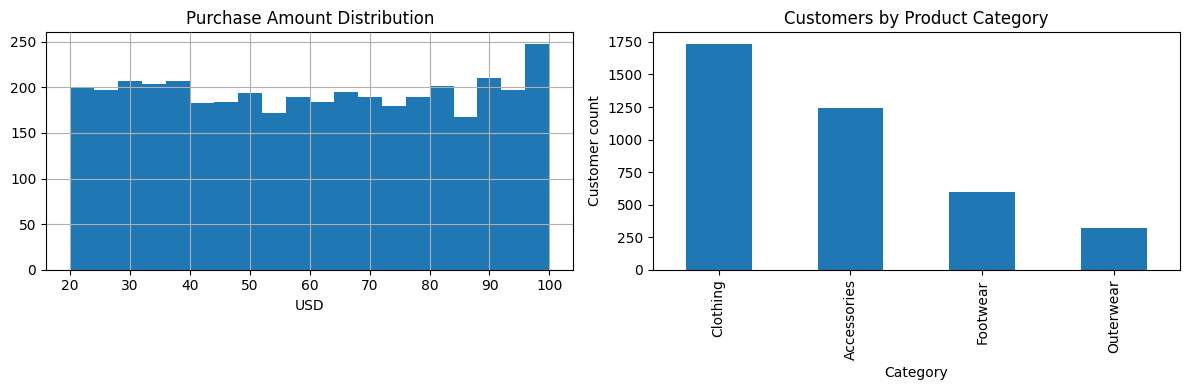

Average purchase amount: 59.76
Average previous purchases: 25.35


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data['Purchase Amount (USD)'].hist(ax=axes[0], bins=20)
axes[0].set_title('Purchase Amount Distribution'); axes[0].set_xlabel('USD')
data['Category'].value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title('Customers by Product Category'); axes[1].set_ylabel('Customer count')
plt.tight_layout(); plt.show()
print('Average purchase amount:', round(data['Purchase Amount (USD)'].mean(), 2))
print('Average previous purchases:', round(data['Previous Purchases'].mean(), 2))


## 4. Feature selection and encoding

`Customer ID` is an identifier, so it is excluded. Numeric features are age, purchase amount, review rating, and previous purchases. Categorical features capture purchase preferences and behaviour. Location, item name, and colour are excluded to avoid high-cardinality noise and overly specific clusters.

## Mathematical justification

**Standardization:** Numeric variables are standardized as \(z=(x-\mu)/\sigma\) so variables measured on larger scales do not dominate Euclidean distance.

**Euclidean distance:** \(d(x_i,\mu_k)=\sqrt{\sum_{j=1}^{p}(x_{ij}-\mu_{kj})^2}\).

**K-Means objective:** \(J=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|^2\). K-Means assigns each record to its nearest centroid and updates centroids to reduce this within-cluster sum of squares.

**Silhouette coefficient:** \(s(i)=(b(i)-a(i))/\max(a(i),b(i))\), where \(a(i)\) is the average within-cluster distance and \(b(i)\) is the lowest average distance to another cluster. Scores near +1 indicate separation; scores near 0 indicate overlap; negative scores can indicate a poor assignment.

**PCA:** PCA projects the processed features onto two directions that capture as much variance as possible for a two-dimensional linear projection. It is used here for plotting; K-Means is fitted on the full processed feature matrix.


In [5]:
numeric_features = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']
categorical_features = ['Gender', 'Category', 'Season', 'Subscription Status', 'Discount Applied', 'Promo Code Used', 'Payment Method', 'Shipping Type', 'Frequency of Purchases']
X = data[numeric_features + categorical_features].copy()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])
X_processed = preprocessor.fit_transform(X)
X_processed = X_processed.toarray() if hasattr(X_processed, 'toarray') else X_processed
print('Processed feature matrix:', X_processed.shape)


Processed feature matrix: (3900, 39)


## 5. Elbow Method and Silhouette Score

,k,inertia,silhouette_score_sample
0,2,32851.084535,0.133830
1,3,31139.191978,0.091747
2,4,29856.681231,0.085466
3,5,28792.320303,0.078579
4,6,27955.663771,0.077842
5,7,27159.057956,0.076568
6,8,26492.128253,0.075952


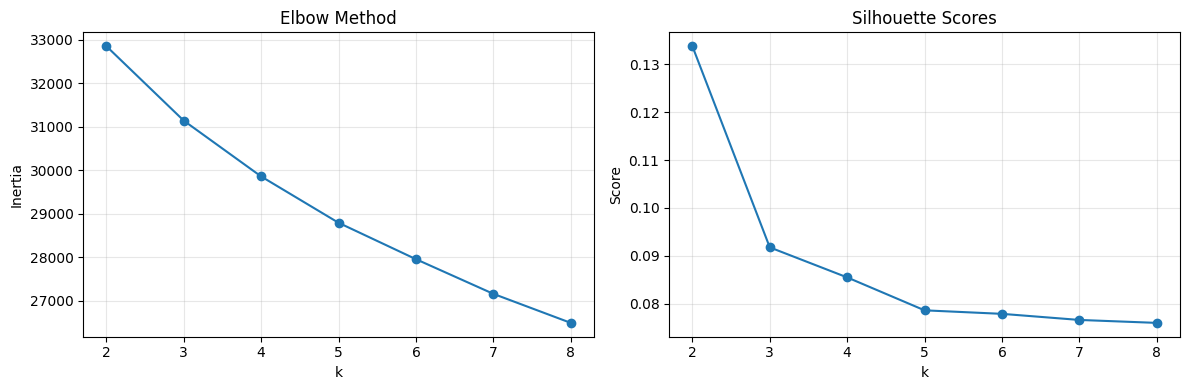

Selected k (highest tested silhouette score): 2


In [6]:
k_values = range(2, 9)
inertias, silhouettes = [], []
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_processed), size=min(1500, len(X_processed)), replace=False)
X_sample = X_processed[sample_idx]
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_processed)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_sample, labels[sample_idx]))
metrics = pd.DataFrame({'k': list(k_values), 'inertia': inertias, 'silhouette_score_sample': silhouettes})
display(metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker='o'); axes[0].set_title('Elbow Method'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia'); axes[0].grid(alpha=.3)
axes[1].plot(list(k_values), silhouettes, marker='o'); axes[1].set_title('Silhouette Scores'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Score'); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
best_k = int(metrics.loc[metrics['silhouette_score_sample'].idxmax(), 'k'])
print('Selected k (highest tested silhouette score):', best_k)


## 6. Final K-Means model

In [7]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
data['Cluster'] = kmeans.fit_predict(X_processed)
print(data['Cluster'].value_counts().sort_index())


Cluster
0    1677
1    2223
Name: count, dtype: int64


## 7. PCA visualization

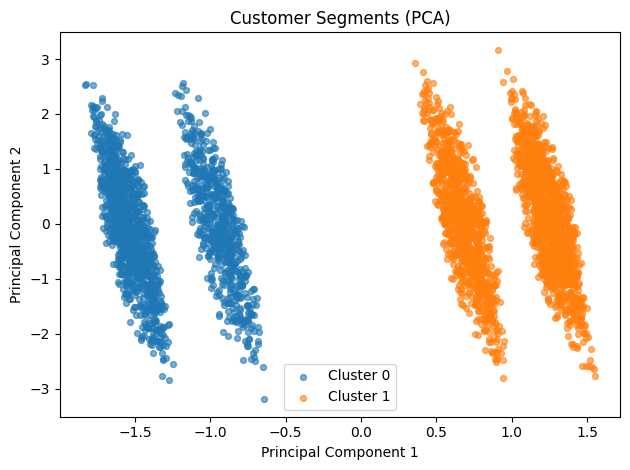

Variance explained by 2 PCs: 0.2514


In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_processed)
data['PCA1'], data['PCA2'] = coords[:, 0], coords[:, 1]
for cluster_id in sorted(data['Cluster'].unique()):
    subset = data[data['Cluster'] == cluster_id]
    plt.scatter(subset['PCA1'], subset['PCA2'], s=18, alpha=.6, label=f'Cluster {cluster_id}')
plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
plt.title('Customer Segments (PCA)'); plt.legend(); plt.tight_layout(); plt.show()
print('Variance explained by 2 PCs:', round(pca.explained_variance_ratio_.sum(), 4))


## 8. Cluster profiles and customer personas

In [9]:
profile = data.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Purchase_USD=('Purchase Amount (USD)', 'mean'),
    Avg_Review_Rating=('Review Rating', 'mean'),
    Avg_Previous_Purchases=('Previous Purchases', 'mean'),
    Subscription_Rate=('Subscription Status', lambda s: (s == 'Yes').mean() * 100),
    Discount_Use_Rate=('Discount Applied', lambda s: (s == 'Yes').mean() * 100),
    Promo_Use_Rate=('Promo Code Used', lambda s: (s == 'Yes').mean() * 100)
).round(2)
display(profile)


,Customers,Avg_Age,Avg_Purchase_USD,Avg_Review_Rating,Avg_Previous_Purchases,Subscription_Rate,Discount_Use_Rate,Promo_Use_Rate
Cluster,,,,,,,,
0,1677,44.14,59.28,3.74,25.74,62.79,100.0,100.0
1,2223,44.01,60.13,3.76,25.06,0.00,0.0,0.0


## Business recommendations

The cluster profiles show that the main difference is recorded discount and promo-code use, while average age, purchase amount, review rating, and previous-purchase count are similar. Test targeted promotions with a control group for discount/promo users. For customers with no recorded discount/promo use, test non-discount engagement such as recommendations or loyalty benefits. Measure incremental conversion and revenue before scaling. These are hypotheses, not proven causal effects.

## Limitations

- The dataset has one customer-level row per customer and no transaction-level history or transaction date. True RFM Recency cannot be calculated; the available purchase amount and previous-purchase count are customer-level fields, not transaction-history-derived Monetary and Frequency metrics.
- The dataset's 2025 publication date does not prove that the records were collected in 2025 or 2026.
- The selected silhouette score is low, indicating weak separation/overlap. The two clusters are mainly distinguished by discount and promo-code indicators; they should not be described as high-value versus low-value customers.
- K-Means uses Euclidean distance and is sensitive to feature representation. One-hot encoded categories contribute to that distance.
- PCA's first two components show only a portion of total variance; the 2D plot is a simplified view.
- Personas are descriptive interpretations, not predictive labels or causal findings.